# MNIST with a neural network built from scratch

This notebook trains the `NeuralNet` class from `neuralnet.py` on MNIST. The class is written in NumPy only: forward pass, backpropagation, softmax with cross-entropy, He initialization, and mini-batch gradient descent. No PyTorch, TensorFlow, or scikit-learn models.

Network: 784 inputs → 128 ReLU → 10 softmax outputs.

## Load the data

MNIST has 70,000 handwritten digits, each a 28×28 grayscale image flattened to 784 pixels. Pixels are scaled from 0–255 to 0–1, which keeps gradients a reasonable size and matches what He initialization assumes. The first run downloads the data and caches it to `mnist.npz`.

In [33]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from neuralnet import NeuralNet  

#figures folder for saving plots
os.makedirs("figures", exist_ok=True)

if os.path.exists("mnist.npz"):
    d = np.load("mnist.npz") 
    X, y = d["X"], d["y"]
else: 
    from sklearn.datasets import fetch_openml
    print("downloading MNIST...")
    m = fetch_openml("mnist_784", version=1, as_frame=False) #numpy array
    X = m.data.astype(np.float32) / 255.0 #convert to decimals and scale 0 to 1: neural net implementation works better with smaller values (nn init assumes small inputs)
    y = m.target.astype(int)
    #save data locally so we dont have to load every time
    np.savez_compressed("mnist.npz", X=X, y=y)






## Train / validation / test split

The first 60,000 images are MNIST's official training set and the last 10,000 are the official test set. I hold out 10,000 of the training images for validation, which I use to watch training. The test set is only used once, at the end.

In [34]:
#split into test and train (first 60k are official training and last 10k are test set)
X_train, X_val = X[:50000], X[50000:60000]
y_train, y_val = y[:50000], y[50000:60000]

X_test = X[60000:]
y_test = y[60000:]
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)


train (50000, 784) val (10000, 784) test (10000, 784)


## A look at the data

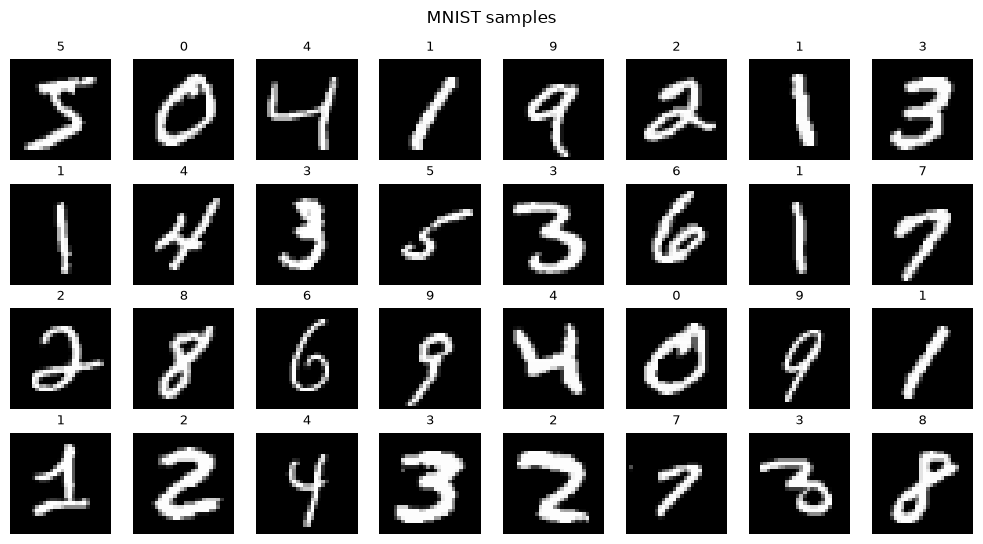

In [35]:
#load some sample digits:
#fig is our figure object and axes are our panels
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5)) #grid of 4 rows, 8 cols of size fig size(which is in inches)

for k,a in enumerate (axes.ravel()): #4x8 grid into flat list of 32 panels then pair each panel a with counter k
    a.imshow(X_train[k].reshape(28,28), cmap="gray") #784 pixels per image need to be reshaped into square to visualize
    a.set_title(str(y_train[k]), fontsize=9)
    a.axis("off") #hides ticks on axes 
fig.suptitle("MNIST samples") #title for plot
fig.tight_layout() #fixes spacing between panels
fig.savefig("figures/1_samples.png", dpi=150) #dpi is resolution


## Train

30 epochs, batch size 128, learning rate 0.1. Each epoch is about 391 weight updates. The log prints training loss and train/validation accuracy after every epoch.

In [36]:
#train
net = NeuralNet(layers=(784, 128, 10), lr = 0.1, epochs= 30, batch_size=128)
#get time before training
t0 = time.time()
net.fit(X_train, y_train, X_val, y_val, log_every=1)
train_time = round(time.time() - t0, 2)
print(f"training took {train_time} seconds")


epoch   0  loss 0.2922  train acc 0.9181  val acc 0.9262
epoch   1  loss 0.2302  train acc 0.9347  val acc 0.9375
epoch   2  loss 0.1947  train acc 0.9455  val acc 0.9486
epoch   3  loss 0.1709  train acc 0.9514  val acc 0.9524
epoch   4  loss 0.1493  train acc 0.9588  val acc 0.9575
epoch   5  loss 0.1384  train acc 0.9608  val acc 0.9594
epoch   6  loss 0.1240  train acc 0.9652  val acc 0.9626
epoch   7  loss 0.1109  train acc 0.9694  val acc 0.9660
epoch   8  loss 0.1036  train acc 0.9715  val acc 0.9661
epoch   9  loss 0.0930  train acc 0.9751  val acc 0.9690
epoch  10  loss 0.0867  train acc 0.9765  val acc 0.9704
epoch  11  loss 0.0817  train acc 0.9777  val acc 0.9707
epoch  12  loss 0.0772  train acc 0.9792  val acc 0.9703
epoch  13  loss 0.0709  train acc 0.9812  val acc 0.9715
epoch  14  loss 0.0664  train acc 0.9821  val acc 0.9724
epoch  15  loss 0.0628  train acc 0.9833  val acc 0.9732
epoch  16  loss 0.0614  train acc 0.9840  val acc 0.9725
epoch  17  loss 0.0578  train a

## Learning curves

Accuracy only checks whether the top guess is right. Loss also accounts for confidence, so the two can tell different stories. Train accuracy keeps rising while validation levels off around 97.5% after roughly epoch 15, which is where the model starts fitting the training set more than it generalizes.

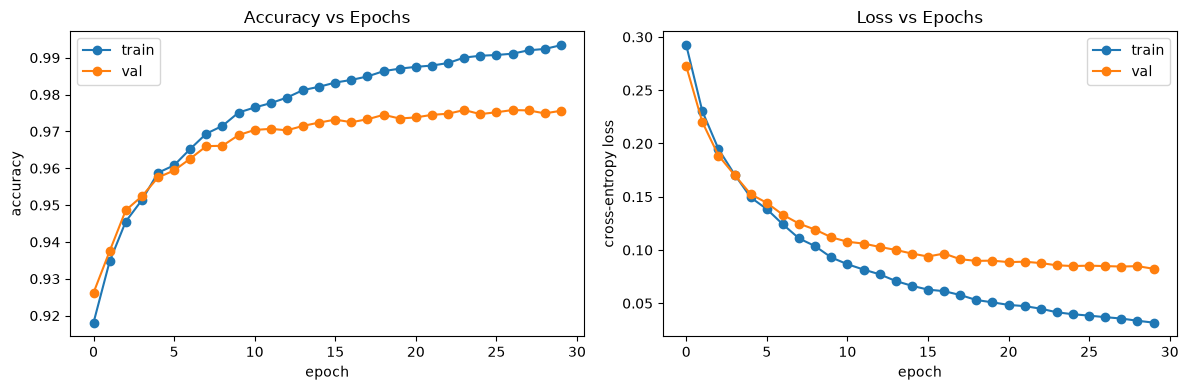

In [37]:
#plot accuracy: 
h = net.history

fig, ax = plt.subplots(1,2, figsize = (12,4))

#plotting accuracy vs epochs
ax[0].plot(h["epoch"], h["train_acc"], "o-", label="train")
ax[0].plot(h["epoch"], h["val_acc"], "o-", label="val")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("accuracy")
ax[0].set_title("Accuracy vs Epochs")
ax[0].legend()

#plotting loss
ax[1].plot(range(len(net.losses)), net.losses, "o-", label="train")
ax[1].plot(h["epoch"], h["val_loss"], "o-", label="val")
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("cross-entropy loss")
ax[1].set_title("Loss vs Epochs")
ax[1].legend()




fig.tight_layout()
fig.savefig("figures/2_AccVsEpochs.png", dpi=150)

## Test set results

Test accuracy: **97.68%** (232 mistakes out of 10,000).

Rows are the true digit and columns are the prediction, so anything off the diagonal is a mistake. The most common confusions are 4 ↔ 9 and 8 → 3.

test accuracy: 0.9768


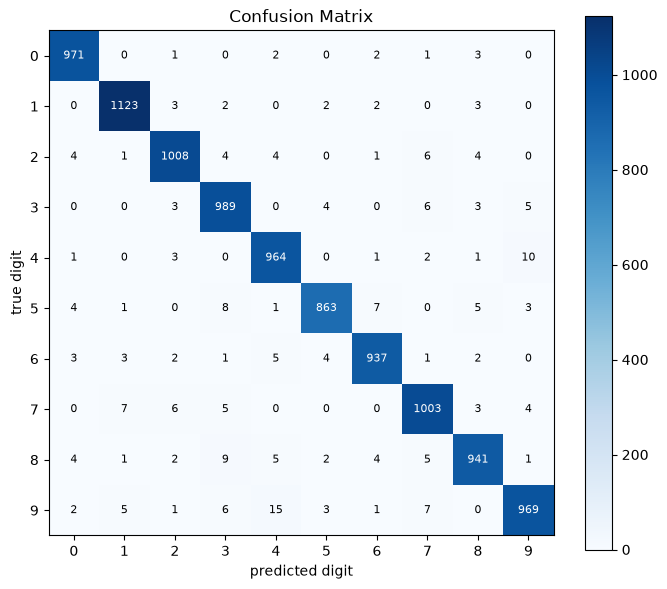

In [38]:
#test
P_test = net.predict_proba(X_test)
preds = P_test.argmax(axis=1)# which digit won
conf_scores = P_test.max(axis=1)# how confident it was
print(f"test accuracy: {np.mean(preds == y_test):.4f}")

#confusion matrix:
conf = np.zeros((10,10), dtype=int)
np.add.at(conf, (y_test, preds), 1)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(conf, cmap="Blues") #draws 2D array as colored squares
for i in range(10):
    for j in range(10):
        #ha are horizontal and vertical allignment then making sure numbers are readible on background color
        ax.text(j,i, conf[i,j], ha="center", va="center", fontsize= 8, color="white" if conf[i,j] > conf.max() / 2 else "black")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("predicted digit")
ax.set_ylabel("true digit")
ax.set_title("Confusion Matrix")
fig.colorbar(im)
fig.tight_layout()
fig.savefig("figures/3_ConfMatrix.png", dpi=150)


## Confident mistakes

The 15 test images the model got wrong while being most sure of its answer. Many of these are hard to read for a person too.

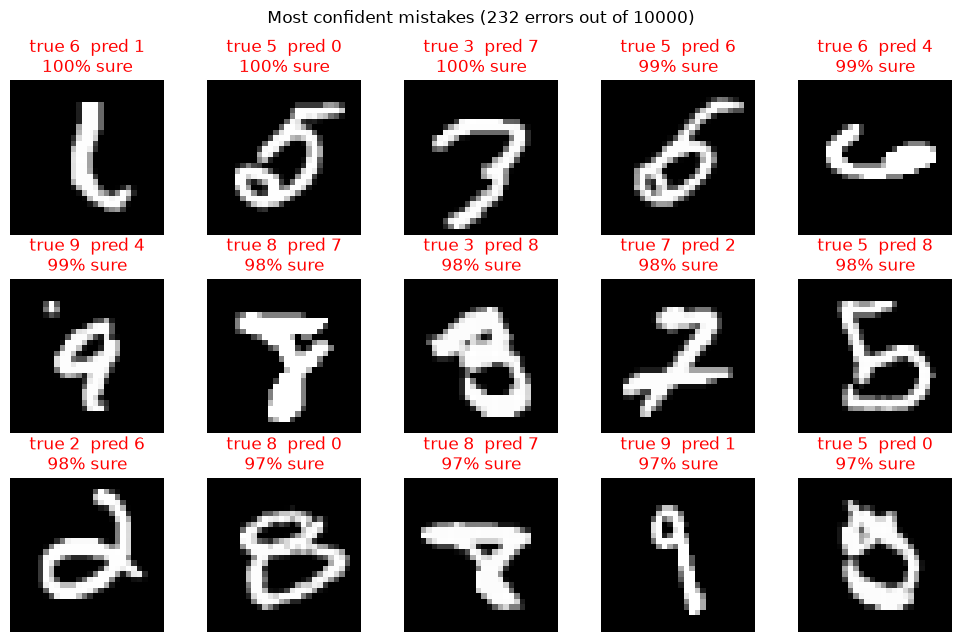

In [39]:
#confidently wrong

wrong = np.where(preds != y_test)[0] #Pull array out of tuple bc we are in 1D
#negate all the wrong scores then return positions of the scores as if they were sorted take the first 15
worst = wrong[np.argsort(-conf_scores[wrong])][:15]

#plot 15 worst
fig, axes = plt.subplots(3, 5, figsize=(10, 6.5)) #3 rows 5 columns
for a, k in zip(axes.ravel(), worst):
    a.imshow(X_test[k].reshape(28, 28), cmap="gray") #show the number 
    a.set_title(f"true {y_test[k]}  pred {preds[k]}\n{conf_scores[k]:.0%} sure", color="red") #show true value and prediction as well as %
    a.axis("off")


fig.suptitle(f"Most confident mistakes ({len(wrong)} errors out of {len(y_test)})")
fig.tight_layout()
fig.savefig("figures/4_mistakes.png", dpi=150)